In [30]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [31]:
#define state
class batsmanState(TypedDict):
    runs: int
    fours: int 
    sixes: int
    balls: int

    strike_rate: float
    boundary_percentage: float
    bpb: float   #balls per boundary 
    summary: str


In [40]:
#define the summary node
def calculate_summary(state: batsmanState)->batsmanState:

    summary=f'strike_rate is {state["strike_rate"]}, \nboundary percentage is {state["boundary_percentage"]}, \nballs per boundary is {state["bpb"]}'

    return {'summary': summary}

In [33]:
#define the calculate strike rate node
def calculate_sr(state: batsmanState)->batsmanState:
    runs=state['runs']
    balls=state['balls']
    sr=(runs/balls)*100

    return {'strike_rate': sr}


In [34]:
#define boundary_percentage node
def calculate_boundary_percentage(state: batsmanState)->batsmanState:
    boundary_per=(state['fours']*4+state['sixes']*6)/state['runs']


    return {'boundary_percentage': boundary_per}

In [35]:
#define the balls per boundary node
def calculate_bpb(state: batsmanState)->batsmanState:
    balls_per_boundary=state['balls']/(state['fours']+state['sixes'])


    return {'bpb': balls_per_boundary}

In [42]:
#create a graph
graph=StateGraph(batsmanState)

#define nodes
graph.add_node('calculate_sr', calculate_sr)
graph.add_node('calculate_boundary_percentage', calculate_boundary_percentage)
graph.add_node('calculate_bpb', calculate_bpb)
graph.add_node('summary', calculate_summary)

#add edges between nodes 
graph.add_edge(START, 'calculate_sr')
graph.add_edge(START, 'calculate_boundary_percentage')
graph.add_edge(START, 'calculate_bpb')

graph.add_edge('calculate_sr', 'summary')
graph.add_edge('calculate_boundary_percentage', 'summary')
graph.add_edge('calculate_bpb', 'summary')

graph.add_edge('summary', END)

workflow=graph.compile()

In [45]:
initial_state={'runs': 50, 'fours': 4, 'sixes': 2, 'balls': 10}
final_state=workflow.invoke(initial_state)

print(final_state['summary'])

strike_rate is 500.0, 
boundary percentage is 0.56, 
balls per boundary is 1.6666666666666667


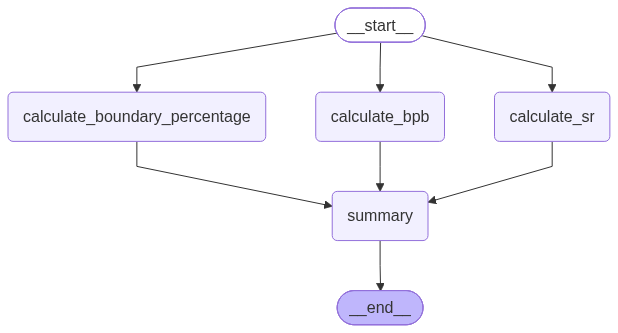

In [46]:
workflow